In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from scipy.linalg import eigh
from scipy.special import genlaguerre, factorial
from scipy.constants import h, electron_volt, value

h_eV = h/electron_volt
mu_B_eV = value('Bohr magneton')/electron_volt

hbar = 1.0
alpha = 1/137
Ha_to_eV = 27.211386


orbitals_list = {0: 's', 1: 'p', 2: 'd', 3: 'f', 4: 'g'}

# Temas Selectos de Física Atómica I
## Actividad 5. Estudio Numérico del Átomo de Sodio
 Ángel André Aguilar Contreras

#### Parámetros para átomos alcalinos

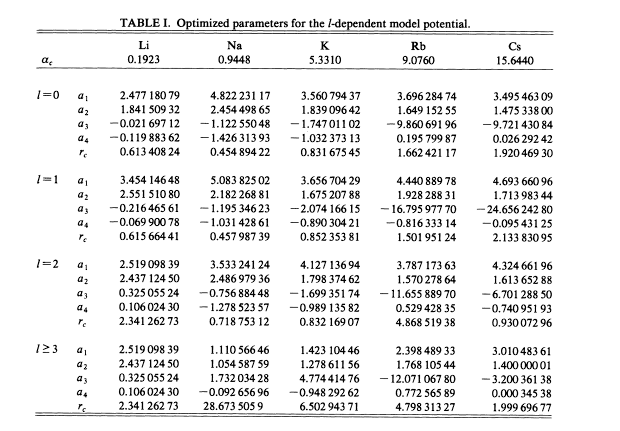

Recuperado de "Dispersion coefficients for alkali-metal atoms", Phys. Rev. A 49, 982 (1994). DOI: https://doi.org/10.1103/PhysRevA.49.982
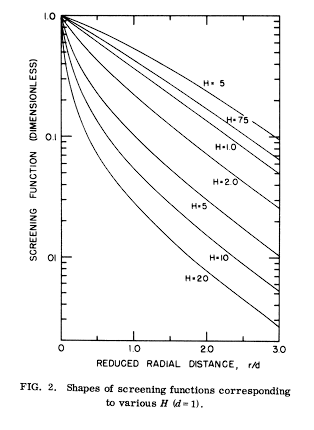 

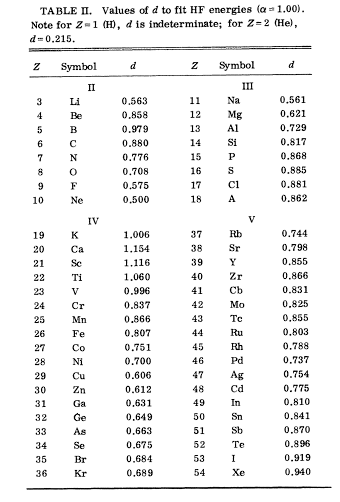 
Recuperado de "Analytic Independent-Particle Model for Atoms", publicado en la revista Physical Review (Vol. 184, 1, 1969). DOI: https://doi.org/10.1103/PhysRev.184.1

In [2]:
with open('alkali_params.json', 'r', encoding='utf-8') as f:
    # Llamamos el json con los datos de las variables empíricas.
    alkali_params = json.load(f)

#### Potenciales Atómicos

In [3]:
def Z_effective(r, l=0, alkali = "H"):
    key_l = str(l if l < 3 else 3)
    Z = alkali_params[alkali]['Z']
    params = alkali_params[alkali][key_l]
    a1 = params['a1']
    a2 = params['a2']
    a3 = params['a3']
    a4 = params['a4']
    return 1 + (Z-1)*np.e**(-a1*r)+ r*(a3+a4*r)*np.e**(-a2*r)

class potential:
    """
    Definimos una clase para guardar los potenciales
    """
    def V_coulomb(r, Z=1): # Potencial Coulombiano
        return -Z/r
        
    def V_carozo(r, l=0, alkali= "H"): # Potencial de Carozo
        key_l = str(l if l < 3 else 3)
        params = alkali_params[alkali][key_l]
        alpha_c = alkali_params[alkali]['alpha_c']
        rc = params['rc']
        return -Z_effective(r=r, alkali=alkali)/r - (alpha_c/(2*r**4))*(1-np.e**(-(r/rc)**6))
        
    def V_GSZ(r, alkali= "H"):
        Z = alkali_params[alkali]['Z']
        H = alkali_params[alkali]['H']
        d = alkali_params[alkali]['d']
        return -(1/r)*(1 + (Z-1)/(H*(np.e**(r/d)-1) +1))
        
    def V_centrifugal (r, l=0): # Potencial Angular (centrífugo)
        return (l*(l + 1)*hbar**2)/(2.0*r**2)
        
    def hydrogen_radial(r, l=0, Z=1.0): # Potencial efectivo del átomo hidrogeneroide.
        return potential.V_coulomb(r=r, Z=Z) + potential.V_centrifugal(r=r, l=l)
        
    def alkali_radial(r, l = 0, alkali= None, p = "carozo"): # Potencial efectivo para átomos alcalinos
        """
        1. Modificar el potencial del átomo de Hidrogeno para estudiar átomos alcalinos
        (que tienen un único electrón de valencia). Esto es, escribir un potencial radial
        efectivo para la parte Coulombiana, Vcarozo(r) que permita incorporar el efecto
        del carozo (los electrones en las capas cerradas).
        """
        if p == "carozo":
            return potential.V_carozo(r=r, l=l, alkali= alkali) + potential.V_centrifugal(r=r, l=l)
        elif p == "GSZ":
            return potential.V_GSZ(r=r, alkali= alkali) + potential.V_centrifugal(r=r, l=l)
        else: print(f"Potencial {potential} no se encuentra en la lista disponible.")

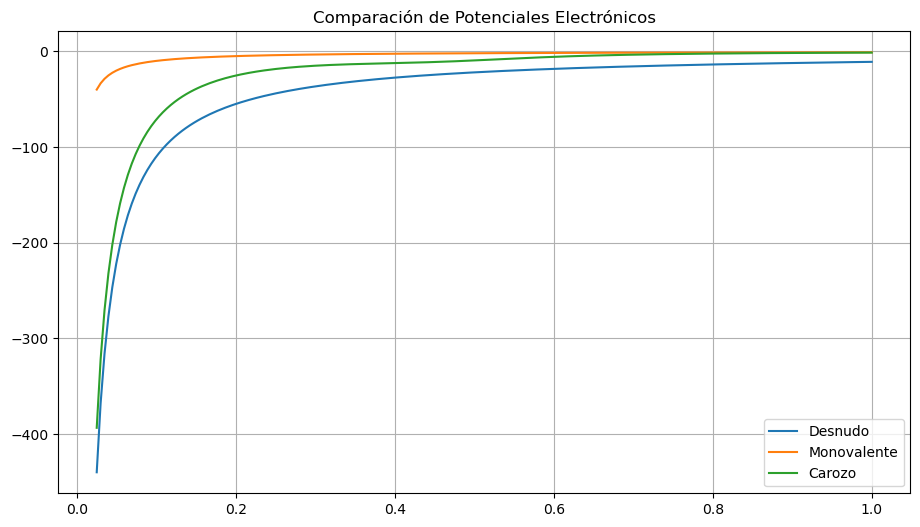

In [4]:
"""
1.a Verifique que esta expresión cumple con los requisitos de límites
asintóticos:
    i. Para r → ∞ : Vcarozo(r) → − 1/r (núcleo al desnudo)
    ii. Para r → 0 : Vcarozo(r) → − Z/r (átomo monovalente)
"""
alkali = "Na"
l = 0

Z = alkali_params[alkali]['Z']
r = np.linspace(0.025, 1, 200)
V_naked = - Z/r
V_mono = -1/r
V_carozo = potential.V_carozo(r=r, l=l, alkali =alkali)

plt.figure(figsize=(11, 6))
plt.plot(r, V_naked, label = "Desnudo")
plt.plot(r, V_mono, label = "Monovalente")
plt.plot(r, V_carozo, label = "Carozo")
plt.title("Comparación de Potenciales Electrónicos")
plt.grid()
plt.legend()
plt.show()

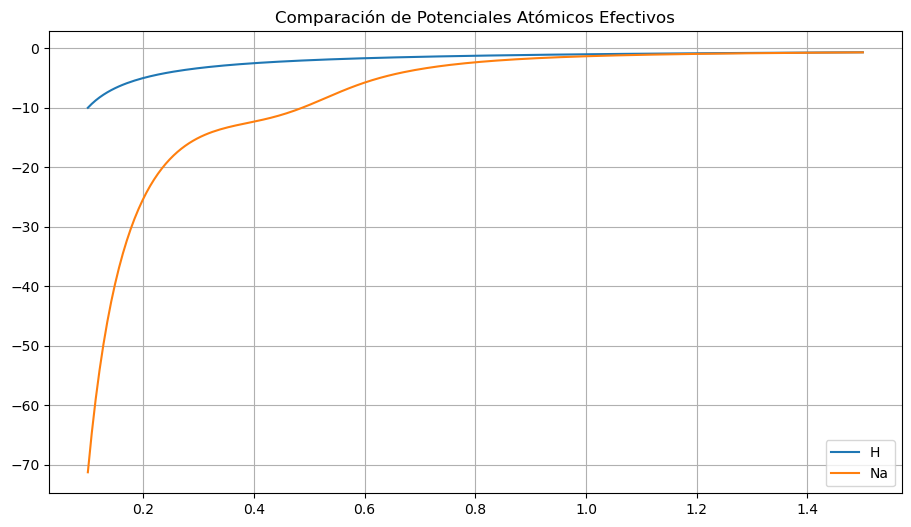

In [5]:
"""
1b. Grafique y compare los potenciales efectivos para H y Na.
"""
alkalis = {"H", "Na"}
l = 0

r = np.linspace(0.1, 1.5, 200)
plt.figure(figsize=(11, 6))
for alkali in alkalis:
    Z = alkali_params[alkali]['Z']
    V = potential.alkali_radial(r=r, l=l, alkali=alkali)
    plt.plot(r, V, label=alkali)
plt.title("Comparación de Potenciales Atómicos Efectivos")
plt.grid()
plt.legend()
plt.show()

#### Funciones Variadas

In [6]:
class solve:
    def hamiltonian(dr, V, N):
        """
        Resuelve la matriz del Hamiltoniano considerando la parte cinética y la parte potencial.
        Calculamos la parte cinética del Hamiltoniano a partir de diferencias finitas centradas.
        d^2(Psi)/dx^2 \approx (Psi_{i+1} - 2 Psi_{i} + Psi_{i-1})/(delta x^2)
        """

        """ Crear la matriz para emplearla en la ecuación de Schrodinger discretizada. """
        constant = -1/(2 * dr**2)
        main_diag = -2*np.ones(N) # multiplicado por -2 sobre la diagonal
        off_diag = np.ones(N-1) # multiplicado por 1 en las secundarias
        T = constant*(np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1))
        H = T + np.diag(V) # Hamiltoniano
        #plot.heatmap(H) # Graficación de la Matriz Hamiltoniana
        return H
        
    @staticmethod
    def get_orbital(n, l, r, alkali = "H", N = 100, p = "carozo"):
        """
        Recupera automáticamente la energía E, función reducida u(r) 
        y función radial R(r) para un número cuántico (n, l) específico.
        """
        if l >= n: raise ValueError(f"Error. l ({l}) debe ser estrictamente menor que n ({n}).")
            
        dr = r[1] - r[0]
        V = potential.alkali_radial(r, l=l, alkali =alkali, p=p)
        """
        Utilizando la parte radial del Hamiltoniano del átomo de hidrogeno, 
        crear la matriz para emplearla en la ecuación de Schrodinger discretizada.
        """
        H = solve.hamiltonian(dr, V, N)
        """
        Utilice herramientas numéricas de algebra lineal para resolver la ecuación de
        eigenvalores. Normalice las eigenfunciones calculadas.
        """
        eigenvalues, eigenfunctions = eigh(H)
        norm = np.trapezoid(eigenfunctions**2, r, axis=0) 
        eigenfunctions /= np.sqrt(norm) 
        
        node = n - l - 1 # Índice de nodo radial i = n - l - 1
        
        energy = eigenvalues[node]
        radial_reduced = eigenfunctions[:, node]
        
        radial = radial_reduced / r
        label = f"{n}{orbitals_list.get(l, f'l={l}')}"
        
        return {'n': n, 'l': l, 'label': label, 'energy': energy, 'radial_reduced': radial_reduced, 'radial': radial}

    @staticmethod
    def get_orbitals_upto(n_min, n_max, r, alkali = "H", N = 100, p = "carozo"):
        """
        Genera una lista con todos los orbitales ordenados desde n=1 hasta n_max 
        barriendo l desde 0 hasta n-1 (ej. 1s, 2s, 2p, 3s, 3p, 3d...).
        """
        orbitals = []
        for n in range(n_min, n_max + 1):
            for l in range(n):
                orb = solve.get_orbital(n=n, l=l, r=r, alkali = alkali, N=N, p=p)
                orbitals.append(orb)
        return orbitals

    @staticmethod
    def get_expval(n, l, r, alkali="H", N=100, p="carozo"):
        """
        Calcular el valor esperado de〈1/r^3〉para obtener la estructura fina del átomo de hidrógeno.
        """
        orb = solve.get_orbital(n=n, l=l, r=r, alkali=alkali, N=N, p=p)
        dr = r[1]- r[0]
        exp_val = np.sum((orb['radial_reduced']**2)*(1/r**3))*dr
        return exp_val
        
    @staticmethod
    def fine_structure(n, l, r, s, alkali = "H", N=100, verbose = True, p="carozo"):
        Z = alkali_params[alkali]['Z']
        if verbose: 
            print(f":::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO {n}{orbitals_list.get(l, f'l={l}').upper()} CON Z={Z}   :::")
        if (l==0): 
            print(f"Para l=0, no hay acoplamiento espín-órbita. Por lo que no hay desdoblamiento \n")
            return
        num_expval = solve.get_expval(n=n, l=l, r=r, alkali=alkali, N=N, p=p)
        j1, j2 = l-s, l+s
        E1 = (Z**2*alpha**2/4)*num_expval*(j1*(j1+1)- l*(l+1) - s*(s+1))*Ha_to_eV
        E2 = (Z**2*alpha**2/4)*num_expval*(j2*(j2+1)- l*(l+1) - s*(s+1))*Ha_to_eV
        dE = np.abs(E2-E1)

        if verbose:
            print(f"Valor esperado de <1/r³>: {num_expval:.6f} a\u2080⁻³")
            print(f"Energía del nivel {n}{orbitals_list.get(l, f'l={l}').upper()}_{int(j1*2)}/2: {E1*1e3:.6f} meV")
            print(f"Energía del nivel {n}{orbitals_list.get(l, f'l={l}').upper()}_{int(j2*2)}/2: {E2*1e3:.6f} meV")
            print(f"Separación energética de la estructura fina: {dE*1e3:.6f} meV ({dE/h_eV*1e-9:.4f} GHz) \n")

        label = f"{n}{orbitals_list.get(l, f'l={l}').upper()}"
        return {'n': n, 'l': l, 'label': label, 'j1':j1, 'j2':j2, 'E1': E1, 'E2': E2}

    def fine_structure_upto(n_min, n_max, r, s=1/2, alkali="H", N=1.0):
        for n in range(n_min, n_max+1):
            for l in range(n):
                _ = solve.fine_structure(n=n, l=l, r=r, s=s, alkali=alkali, N=N)

In [7]:
class analytical:
    @staticmethod
    def radial(n, l, r, Z=1.0):
        """Calcula la función radial analítica R_{n,l}(r) exacta."""
        rho = (2.0 * Z * r) / n
        norm = np.sqrt((2.0 * Z / n)**3 * factorial(n - l - 1) / (2.0 * n * factorial(n + l))) # Factor de normalización
        L = genlaguerre(n - l - 1, 2 * l + 1) # Polinomio asociado de Laguerre 
        return norm * np.exp(-rho / 2.0) * (rho**l) * L(rho)

    @staticmethod
    def radial_reduced(n, l, r, Z=1.0):
        """Calcula la función u_{n,l}(r) = r * R(r)."""
        return r * analytical.radial(n, l, r, Z)

    @staticmethod
    def energy(n, Z=1.0):
        """Energía analítica del átomo de hidrógeno: E_n = -Z^2 / (2 * n^2) en Hartree."""
        return -0.5 * (Z**2) / (n**2)

    @staticmethod
    def get_orbital(n,l,r,Z = 1.0):
        radial = analytical.radial(n, l, r, Z)
        radial_reduced = analytical.radial_reduced(n, l, r, Z)
        energy = analytical.energy(n,Z)
        label = f"{n}{orbitals_list.get(l, f'l={l}')}"
        return {'n': n, 'l': l, 'label': label, 'energy': energy, 'radial_reduced': radial_reduced, 'radial': radial}

In [8]:
class plot:
    def heatmap(H):
        """
        Grafica la matriz en un mapa de color para visualizar los elementos relevantes. 
        """
        fig = plt.figure(figsize=(6, 6))
        im = plt.imshow(H, cmap='inferno', aspect='equal')
        fig.colorbar(im, fraction=0.046, pad=0.04, label="Energía")
        plt.title('Heatmap de la Matriz Hamiltoniana')
        plt.xlabel('Columna [Índice i]')
        plt.ylabel('Fila [Índice j]')
        
        plt.show()
        
    def solution(orbitals, r, **kargs):
        """
        Grafica los orbitales respecto a laa coordenada radial con sus respectivas energías.
        """
        label, xlim, ylim = kargs.get('label', ''), kargs.get('xlim', (-1,1)) ,kargs.get('ylim', (-1,1))
        
        plt.figure(figsize=(11, 6))

        """
        3. Grafique las funciones de onda y las energías del sistema. Como mínimo, utilice los primeros 5 estados.
        """
        for i, orb in enumerate(orbitals):
            (line,) = plt.plot(r, np.abs(orb['radial_reduced'])**2 + orb['energy'], 
                               label = f"$|u(r)|^2$, {orb['label']:<3}, E = {orb['energy']*Ha_to_eV:.4f} eV")
            color = line.get_color()
            plt.hlines(orb['energy'], r[0], r[-1], color = color, linestyle=':', alpha=0.5)
            
        plt.xlim(xlim)
        plt.ylim(ylim)
        
        plt.xlabel('Distancia radial [r] ($a_0$)')
        plt.ylabel('Energias y norma de las funciones radiales (Ha)')
        plt.title(f'Soluciones al Átomo {label}')
        plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left', borderaxespad=0., fontsize=10)
        plt.grid()
        
        plt.tight_layout()
        plt.show()

    def compare(numerical, analytical):
        fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 5))
        
        ax.plot(r, analytical['radial_reduced'], 'b-', linewidth=1, label=f'$u(r)$ analítica, {numerical['label']}')
        ax.plot(r, numerical['radial_reduced'], 'r--', linewidth=1, label=f'$u(r)$ numérica, {numerical['label']}')
        ax.set_title(f"Función de Radial Reducida $u(r)$")
        ax.set_xlabel('Distancia radial $r$ ($a_0$)')
        ax.set_ylabel('$u(r)$')
        ax.legend()
        ax.grid()
        
        bx.plot(r, analytical['radial_reduced']**2, 'k-', linewidth=1, label=f'$|u(r)|^2$ analítica, {numerical['label']}')
        bx.plot(r, numerical['radial_reduced']**2, 'r--', linewidth=1, label=f'$|u(r)|^2$ numérica, {numerical['label']}')
        bx.set_title(f"Densidad de Probabilidad Radial $|u(r)|^2$")
        bx.set_xlabel('Distancia radial [r] ($a_0$)')
        bx.set_ylabel('$|u(r)|^2$')
        bx.legend()
        bx.grid()
        
        plt.tight_layout()
        plt.show()

In [9]:
class compare:
    @staticmethod
    def orbitals(r, orbital1, orbital2, **kargs):
        """
        Compara dos orbitales en energías y funciones de onda.
        """
        labels = kargs.get('labels', '')
        xlim, ylim = kargs.get('xlim', (-1,1)) , kargs.get('ylim', (-1,1))
        plt.figure(figsize=(11, 6))
        print(f':::      COMPARACIÓN DE ORBITALES PARA {labels[0]} y {labels[1]}     :::\n')
        for i, orb in enumerate([orbital1, orbital2]):
            print(f'Energía del orbital {orb['label']:<3}para {labels[i]}: {orb['energy']*Ha_to_eV:.4f} eV')
            (line,) = plt.plot(r, np.abs(orb['radial_reduced'])**2 + orb['energy'], 
                               label = f"$|u(r)|^2$, [{labels[i]}] {orb['label']:<3}, E = {orb['energy']*Ha_to_eV:.4f} eV")
            color = line.get_color()
            plt.hlines(orb['energy'], r[0], r[-1], color = color, linestyle=':', alpha=0.5)
        delta = np.abs(orbital1['energy'] - orbital2['energy'])
        print(f'Diferencia energética: {delta*Ha_to_eV:.4f} eV \n')
        plt.xlim(xlim)
        plt.ylim(ylim)
        
        plt.xlabel('Distancia radial [r] ($a_0$)')
        plt.ylabel('Energias y norma de las funciones radiales (Ha)')
        plt.title(f'Comparaciones de Orbitales para {labels[0]} y {labels[1]}')
        plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left', borderaxespad=0., fontsize=10)
        plt.grid()
        
        plt.tight_layout()
        plt.show()

#### Soluciones a Átomos Alcalinos

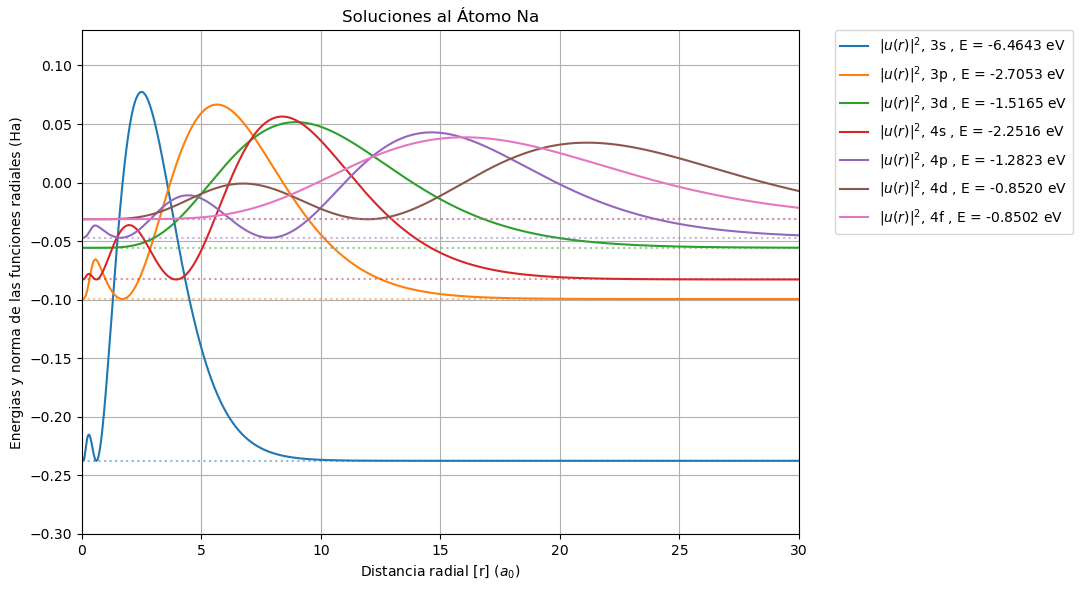

In [10]:
"""
2. Utilizando el potencial efectivo para crear la matriz empleada en la ecuación de
Schrodinger discretizada y las herramientas numéricas de algebra lineal para
resolver la ecuación de eigenvalores. Normalice las eigenfunciones calculadas.

3. Grafique las funciones de onda y las energías del sistema. Como mínimo, utilice
los primeros 5 estados.
"""
# Variables de Simulación
L = 50.0
lim = 30
N = 2000
alkali = "Na"
n_min = 3
n_max = 4

# Simulación
r = np.linspace(1e-2, L, N)
Na_orbitals = solve.get_orbitals_upto(n_min = n_min, n_max=n_max, r=r, alkali=alkali, N=N)
plot.solution(Na_orbitals, r, xlim = (0,lim), ylim = (-0.3, 0.13), label = f"{alkali}")

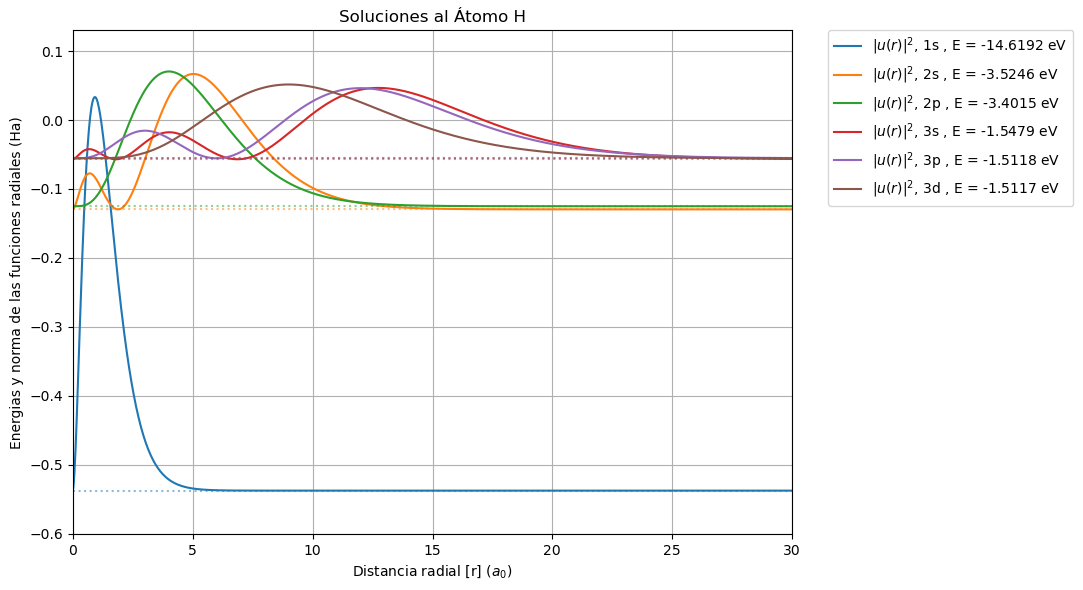

In [11]:
"""
4. Compare las funciones de onda del Na con las funciones de onda del H.
Compare también los valores de la energía. Utilice el estado fundamental y
algún otro estado excitado de su elección.
"""
# Variables de Simulación
L = 50.0
lim = 30
N = 2000
alkali = "H"
n_min = 1
n_max = 3

# Simulación
r = np.linspace(1e-2, L, N)
H_orbitals = solve.get_orbitals_upto(n_min = n_min, n_max=n_max, r=r, alkali=alkali, N=N)
plot.solution(H_orbitals, r, xlim = (0,lim), ylim = (-0.6, 0.13), label = f"{alkali}")

:::      COMPARACIÓN DE ORBITALES PARA Na y H     :::

Energía del orbital 3s para Na: -6.4643 eV
Energía del orbital 1s para H: -14.6192 eV
Diferencia energética: 8.1548 eV 



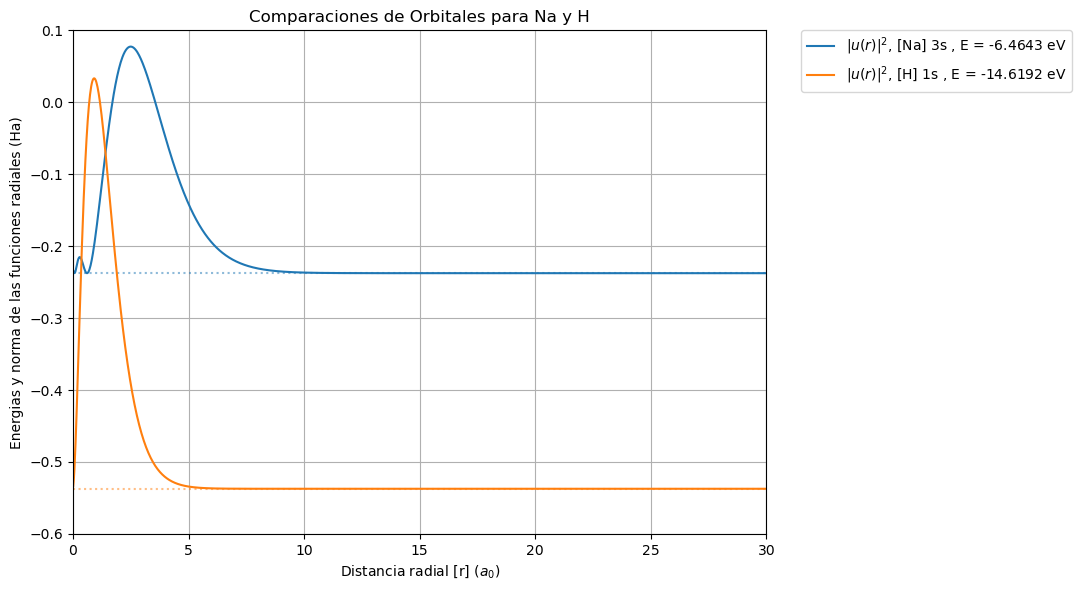

In [12]:
compare.orbitals(r, Na_orbitals[0], H_orbitals[0], xlim = (0, lim), ylim = (-0.6, 0.1), labels = ("Na", "H"))

:::      COMPARACIÓN DE ORBITALES PARA Na y H     :::

Energía del orbital 3p para Na: -2.7053 eV
Energía del orbital 2s para H: -3.5246 eV
Diferencia energética: 0.8193 eV 



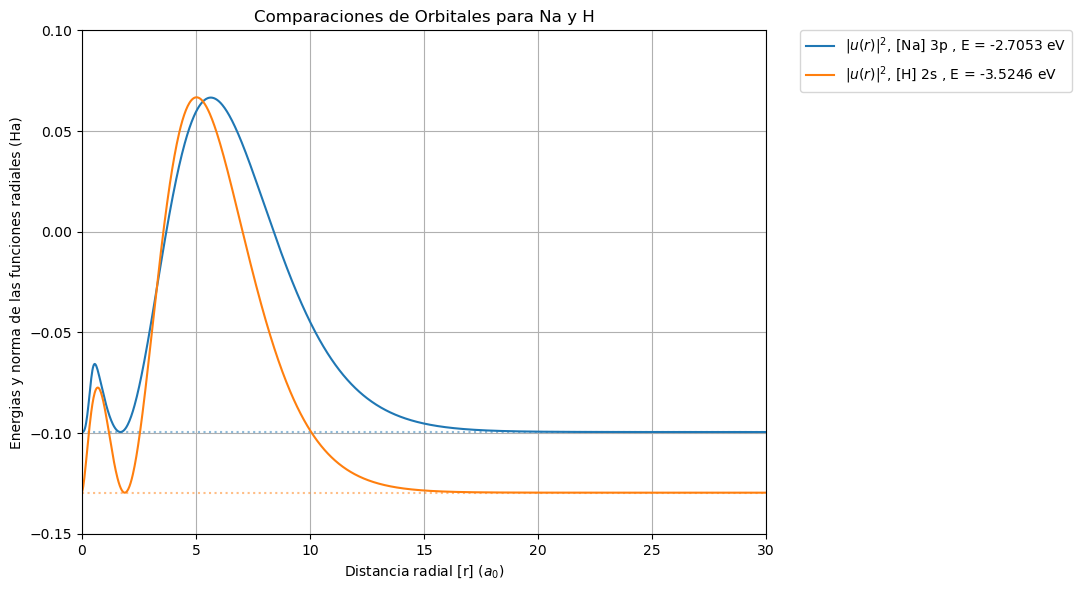

In [13]:
compare.orbitals(r, Na_orbitals[1], H_orbitals[1], xlim = (0, lim), ylim = (-0.15, 0.1), labels = ("Na", "H"))

In [14]:
"""
CORRECCIÓN DE ESTRUCTURA FINA.
5. Calcular el valor esperado de 〈1/r^3〉para obtener la estructura fina del Na.
6. Obtener la separación en energía de la estructura fina para los estados 1S, 2S,
2P, 3S, 3P, 3D.

En realidad se obtiene para  los estados 3S, 3P, 3D, 4S, 4P, 4D, 4F.
"""
s = 1/2
alkali = "H"
n_min = 3
n_max = 4
solve.fine_structure_upto(n_min = n_min, n_max= n_max, r=r, s=s, alkali=alkali, N=N)

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 3S CON Z=1   :::
Para l=0, no hay acoplamiento espín-órbita. Por lo que no hay desdoblamiento 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 3P CON Z=1   :::
Valor esperado de <1/r³>: 0.012346 a₀⁻³
Energía del nivel 3P_1/2: -0.008950 meV
Energía del nivel 3P_3/2: 0.004475 meV
Separación energética de la estructura fina: 0.013425 meV (3.2461 GHz) 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 3D CON Z=1   :::
Valor esperado de <1/r³>: 0.002469 a₀⁻³
Energía del nivel 3D_3/2: -0.002685 meV
Energía del nivel 3D_5/2: 0.001790 meV
Separación energética de la estructura fina: 0.004475 meV (1.0820 GHz) 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 4S CON Z=1   :::
Para l=0, no hay acoplamiento espín-órbita. Por lo que no hay desdoblamiento 

:::   CORRECCIÓN DE ESTRUCTURA FINA PARA EL ESTADO 4P CON Z=1   :::
Valor esperado de <1/r³>: 0.005274 a₀⁻³
Energía del nivel 4P_1/2: -0.003823 meV
Energía del nivel 4P_3/2: 0.001912 meV

#### Potencial de Green-Sellin-Zachor (GSZ)

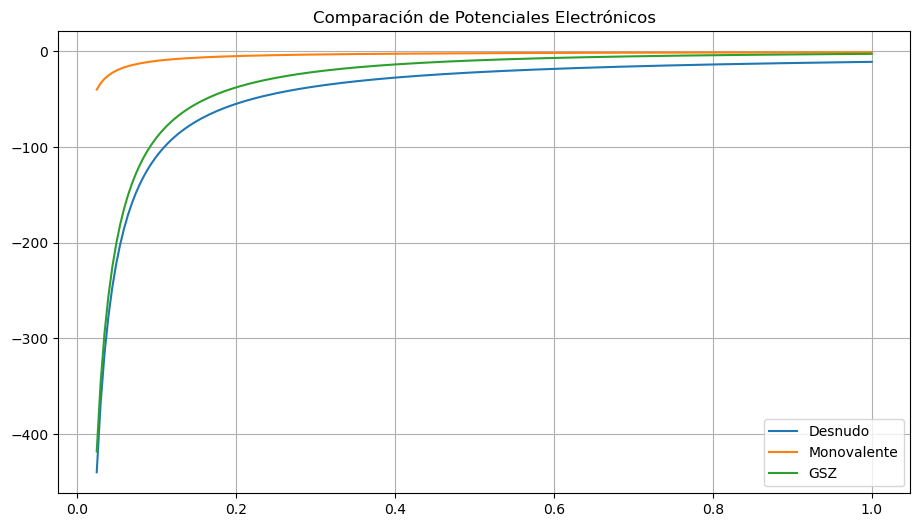

In [15]:
"""
7. Repita los puntos 1 y dos pero utilizando la expresión del Potencial
Parametrizado de Green-Sellin-Zachor (GSZ)
"""

"""
1.a Verifique que esta expresión cumple con los requisitos de límites
asintóticos:
    i. Para r → ∞ : Vcarozo(r) → − 1/r (núcleo al desnudo)
    ii. Para r → 0 : Vcarozo(r) → − Z/r (átomo monovalente)
"""
alkali = "Na"

Z = alkali_params[alkali]['Z']
r = np.linspace(0.025, 1, 200)
V_naked = - Z/r
V_mono = -1/r
V_GSZ = potential.V_GSZ(r=r, alkali =alkali)

plt.figure(figsize=(11, 6))
plt.plot(r, V_naked, label = "Desnudo")
plt.plot(r, V_mono, label = "Monovalente")
plt.plot(r, V_GSZ, label = "GSZ")
plt.title("Comparación de Potenciales Electrónicos")
plt.grid()
plt.legend()
plt.show()

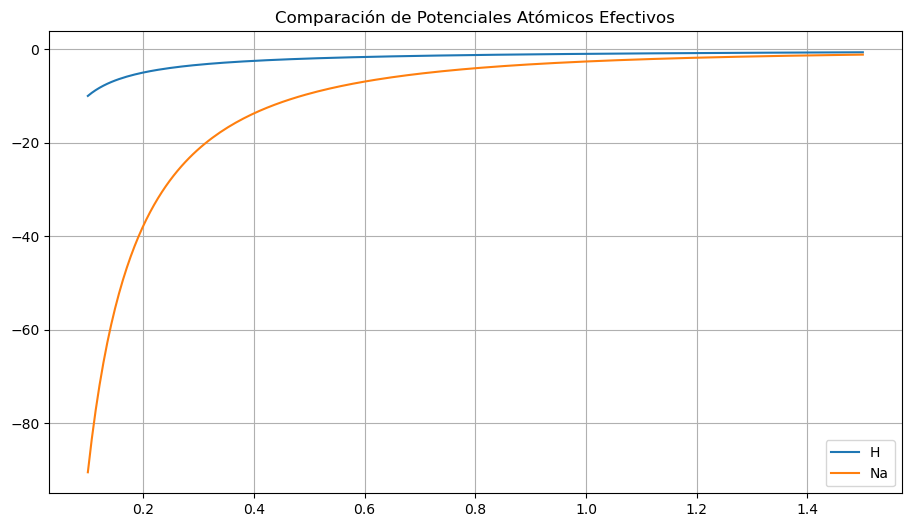

In [16]:
"""
1b. Grafique y compare los potenciales efectivos para H y Na.
"""

alkalis = {"H", "Na"}
l = 0

r = np.linspace(0.1, 1.5, 200)
plt.figure(figsize=(11, 6))
for alkali in alkalis:
    Z = alkali_params[alkali]['Z']
    V = potential.alkali_radial(r=r, l=l, alkali=alkali, p="GSZ")
    plt.plot(r, V, label=alkali)
plt.title("Comparación de Potenciales Atómicos Efectivos")
plt.grid()
plt.legend()
plt.show()

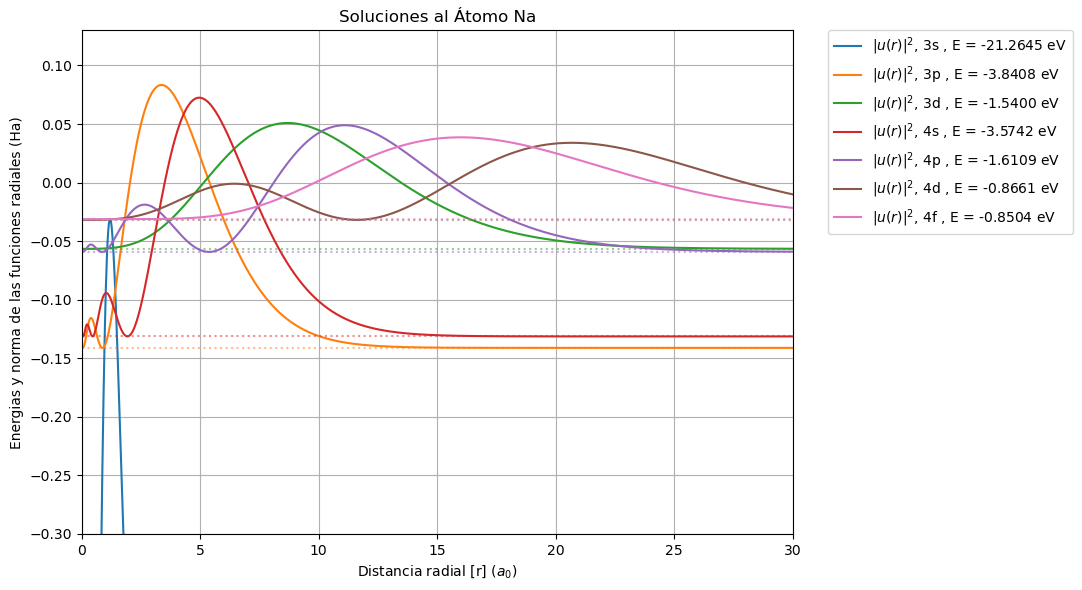

In [17]:
"""
2. Utilizando el potencial efectivo para crear la matriz empleada en la ecuación de
Schrodinger discretizada y las herramientas numéricas de algebra lineal para
resolver la ecuación de eigenvalores. Normalice las eigenfunciones calculadas.

3. Grafique las funciones de onda y las energías del sistema. Como mínimo, utilice
los primeros 5 estados.
"""
# Variables de Simulación
L = 50.0
lim = 30
N = 2000
alkali = "Na"
n_min = 3
n_max = 4

# Simulación
r = np.linspace(1e-2, L, N)
Na_orbitals = solve.get_orbitals_upto(n_min = n_min, n_max=n_max, r=r, alkali=alkali, N=N, p="GSZ")
plot.solution(Na_orbitals, r, xlim = (0,lim), ylim = (-0.3, 0.13), label = f"{alkali}")